# Упражнения по Supervised Lerning и методу K ближайших соседей

# Цели обучения:

- Объяснить суть обучения с учителем и способы его применения к задачам регрессии и классификации
- Применять алгоритм K ближайших соседей (KNN) для классификации
- Использовать расширение Intel® для Scikit-learn*, чтобы задействовать вычислительные возможности аппаратного обеспечения



## Введение

Для выполнения заданий первой недели мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли. Файл данных называется
`Orange_Telecom_Churn_Data.csv`. Мы вместе загрузим эти данные, проведем их предварительную обработку и воспользуемся алгоритмом K ближайших соседей для прогнозирования оттока клиентов на основе характеристик учетных записей.

In [37]:
from __future__ import print_function
import os
data_path = ['..', 'data']

from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

## Вопрос 1

* Начните с импорта данных. Изучите столбцы и данные.
* Обратите внимание, что данные содержат штат, телефонный код и номер телефона. Как вы считаете, подходят ли эти признаки для построения модели машинного обучения? Почему да или почему нет?

In [38]:
import pandas as pd

filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)

In [39]:
data.head(1).T

,0
state,KS
account_length,128
area_code,415
phone_number,382-4657
intl_plan,no
voice_mail_plan,yes
number_vmail_messages,25
total_day_minutes,265.1
total_day_calls,110
total_day_charge,45.07


### Эти три признака для модели не подходят.

**Номер телефона (phone_number):**
- у каждого клиента он уникальный, поэтому мы не найдем закономерность, что у клиенты с такими номерами уходят чаще;
- модель могла бы просто запомнить конкретные номера и угадывать ответы на обучающих данных. На новых клиентах это не работает, то есть получается переобучение;
- телефон является строкой вида 382-4657, чтобы KNN её использовал, пришлось бы превращать её в число, а расстояние между такими числами ничего не значит;

**Штат (state) и код региона (area_code):**
- эти два признака являются категориальными, а не количественными. Код 510 не больше кода 408, а штат KS не дальше от OH, чем от CA;
- one-hot кодирование, добавила бы около 50 новых столбцов для штатов. В KNN все признаки равноправны по вкладу в расстояние, поэтому эти столбцы заглушили бы по-настоящему важные: звонки в поддержку, минуты разговоров, международный план;


In [40]:
data.drop(['state', 'area_code', 'phone_number'], axis=1, inplace=True)

In [41]:
data.columns

Index(['account_length', 'intl_plan', 'voice_mail_plan',
       'number_vmail_messages', 'total_day_minutes', 'total_day_calls',
       'total_day_charge', 'total_eve_minutes', 'total_eve_calls',
       'total_eve_charge', 'total_night_minutes', 'total_night_calls',
       'total_night_charge', 'total_intl_minutes', 'total_intl_calls',
       'total_intl_charge', 'number_customer_service_calls', 'churned'],
      dtype='str')

## Вопрос 2

* Обратите внимание, что некоторые столбцы содержат категориальные данные, а другие — численные. Эти признаки необходимо кодировать в числовом виде с помощью одного из методов, рассмотренных на лекции.
* Наконец, помните из лекции, что для алгоритма «K ближайших соседей» требуются нормированные данные. Нормируйте данные с помощью одного из методов нормирования, рассмотренных на лекции.

Столбцы ```intl_plan``` , ```voice_mail_plan``` и ```churned``` содержали «yes/no» и
«True/False». ```LabelBinarizer``` превратил их в 0 и 1.

In [42]:
lb = LabelBinarizer()

for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    data[col] = lb.fit_transform(data[col])

```MinMaxScaler``` привёл все столбцы к диапазону от 0 до 1. KNN считает
расстояния между клиентами, и без этого шага столбец с минутами (сотни)
перебил бы столбец со звонками в поддержку (единицы).

In [43]:
import warnings
warnings.filterwarnings('ignore', module='sklearn')

msc = MinMaxScaler()

data = pd.DataFrame(msc.fit_transform(data), 
                    columns=data.columns)

## Вопрос 3

* Разделите столбцы признаков (все, кроме `churned`) и метку (`churned`). В результате будут созданы две таблицы.
* Постройте модель «K ближайших соседей» со значением `k=3` на этих данных и спрогнозируйте результат на тех же данных.

In [44]:
x_cols = [x for x in data.columns if x != 'churned']

X_data = data[x_cols]
y_data = data['churned']

In [45]:
knn = KNeighborsClassifier(n_neighbors=3)
knn = knn.fit(X_data, y_data)
y_pred = knn.predict(X_data)

## Вопрос 4

Способы измерения погрешности на занятиях пока не обсуждались, но понятие точности легко понять — это просто процент правильно предсказанных меток (истинных или ложных).

* Напишите функцию для вычисления точности с использованием фактических и предсказанных меток.
* С помощью этой функции вычислите точность данной модели «K ближайших соседей» для данного набора данных.

In [53]:
def accuracy(real, predict):
    return sum(real == predict) / float(real.shape[0])

Точность — это доля правильных ответов. Для ```k=3``` получилось 0.9422, то
есть около 94%.

In [47]:
print(accuracy(y_data, y_pred))

0.9422


## Вопрос 5

* Снова обучите модель «K ближайших соседей» с параметром `n_neighbors=3`, но на этот раз используйте расстояние в качестве весов. Рассчитайте точность с помощью функции, которую вы создали выше.
* Обучите ещё одну модель «K ближайших соседей». На этот раз используйте равномерные веса, но установите параметр степени для метрики расстояния Минковского равным 1 (`p=1`), т. е. расстояние Манхэттена.

Когда в части 1 этого вопроса используются взвешенные расстояния, в качестве точности должно возвращаться значение 1,0. Почему, по-вашему, так происходит? *Подсказка:* мы строим прогнозы на данных, а в случае KNN модель *и есть* данные. В следующей лекции мы узнаем, как избежать этой ловушки.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn = knn.fit(X_data, y_data)
y_pred = knn.predict(X_data)
print(accuracy(y_data, y_pred))

1.0


С весами по расстоянию ( ```weights='distance'``` ) точность равна 1.0, потому что проверяем модель на тех же данных, на которых она училась. У KNN модель и есть сами данные. Когда клиент ищет ближайших соседей, самым близким оказывается он сам, на расстоянии 0. 

Такой сосед получает огромный вес и перевешивает остальных, поэтому ответ всегда правильный. Это не значит, что
модель хорошая: она просто списывает с собственной шпаргалки. На новых клиентах точность была бы ниже.

In [55]:
knn = KNeighborsClassifier(n_neighbors=3, p=1)
knn = knn.fit(X_data, y_data)
y_pred = knn.predict(X_data)
print(accuracy(y_data, y_pred))

0.9456


При ```p=2``` (Евклидово расстояние) большие различия по одному признаку сильно выделяются, потому что их возводят в квадрат. Один сильно отличающийся признак может перетянуть расстояние.

При ```p=1``` (расстояние Манхэттена) все различия учитываются пропорционально, без усиления больших. Он спокойнее относится к выбросам и часто лучше работает, когда признаков много.

## Вопрос 6

* Постройте модель K ближайших соседей, используя значения `k` (`n_neighbors`) в диапазоне от 1 до 20. Используйте равномерные веса (по умолчанию). Коэффициент расстояния Минковского (`p`) можно установить равным 1 или 2 — главное, чтобы значение оставалось неизменным. Сохраните точность и значение `k`, использованное при каждой из этих подгонок, в списке или словаре.
* Постройте график (или просмотрите таблицу) зависимости `accuracy` от `k`. Что вы заметили, когда `k=1`? Почему, по-вашему, так происходит? *Подсказка:* причина та же, что и обсуждалась выше.

In [56]:
score_list = list()

for k in range(1, 21):
    
    knn = KNeighborsClassifier(n_neighbors=k)
    knn = knn.fit(X_data, y_data)
    
    y_pred = knn.predict(X_data)
    score = accuracy(y_data, y_pred)
    
    score_list.append((k, score))
    
score_df = pd.DataFrame(score_list, columns=['k', 'accuracy'])

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

Видно, как точность зависит от ```k```. 

При ```k=1``` она равна 1.0, потому что единственный ближайший сосед клиента это он сам. С ростом k точность падает, так как модель усредняет ответ по большему числу соседей.

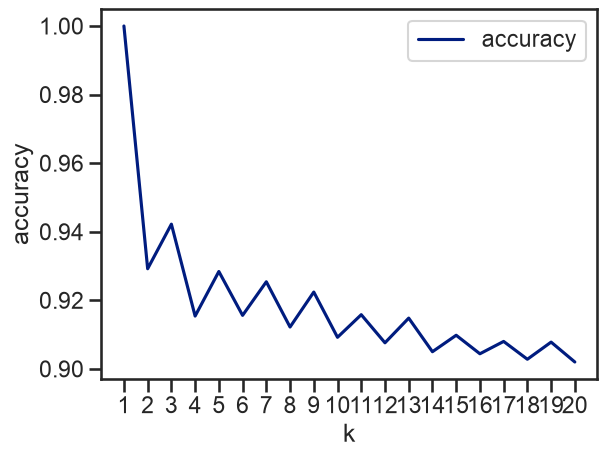

In [58]:
sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

ax = score_df.set_index('k').plot()

ax.set(xlabel='k', ylabel='accuracy')
ax.set_xticks(range(1, 21));